In [3]:
import pandas as pd
import numpy as np
import joblib

df_model = pd.read_csv("data/interim/train_cleaned_v1.csv")
X = df_model.drop("SeriousDlqin2yrs", axis=1)
y = df_model["SeriousDlqin2yrs"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

xgb = joblib.load("models/xgboost_v1.pkl")
y_prob = xgb.predict_proba(X_test)[:, 1]

print("Test set size:", X_test.shape)
print("y_prob sample:", y_prob[:5])

Test set size: (29946, 10)
y_prob sample: [0.77109396 0.4781493  0.7914553  0.07603469 0.23549059]


In [4]:
# Cost assumption (stated explicitly, not measured from real financial data):
# Approving a defaulter (False Negative) costs COST_FN units.
# Rejecting a good borrower (False Positive) costs COST_FP units (lost profit margin).
# We assume a 5:1 ratio as a commonly-cited starting point in credit risk literature.
COST_FN = 5.0
COST_FP = 1.0

In [5]:
from sklearn.metrics import confusion_matrix

thresholds = np.arange(0.05, 0.95, 0.01)
results = []

for t in thresholds:
    y_pred = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    expected_loss = (fn * COST_FN) + (fp * COST_FP)
    results.append({"threshold": t, "fn": fn, "fp": fp, "expected_loss": expected_loss})

results_df = pd.DataFrame(results)
optimal_row = results_df.loc[results_df["expected_loss"].idxmin()]
print(optimal_row)

threshold           0.72
fn                907.00
fp               1971.00
expected_loss    6506.00
Name: 67, dtype: float64


In [6]:
for t in [0.1, 0.3, 0.5, 0.6, 0.72, 0.8, 0.9]:
    row = results_df.loc[(results_df["threshold"] - t).abs().idxmin()]
    print(row.to_dict())

{'threshold': 0.1, 'fn': 26.0, 'fp': 21822.0, 'expected_loss': 21952.0}
{'threshold': 0.30000000000000004, 'fn': 235.0, 'fp': 10395.0, 'expected_loss': 11570.0}
{'threshold': 0.5000000000000001, 'fn': 464.0, 'fp': 5613.0, 'expected_loss': 7933.0}
{'threshold': 0.6000000000000002, 'fn': 682.0, 'fp': 3628.0, 'expected_loss': 7038.0}
{'threshold': 0.7200000000000002, 'fn': 907.0, 'fp': 1971.0, 'expected_loss': 6506.0}
{'threshold': 0.8000000000000002, 'fn': 1094.0, 'fp': 1244.0, 'expected_loss': 6714.0}
{'threshold': 0.9000000000000002, 'fn': 1450.0, 'fp': 434.0, 'expected_loss': 7684.0}


In [7]:
import matplotlib.pyplot as plt
plt.plot(results_df["threshold"], results_df["expected_loss"])
plt.axvline(optimal_row["threshold"], color="red", linestyle="--", label="Optimal threshold")
plt.xlabel("Threshold")
plt.ylabel("Expected Loss (cost units)")
plt.title("Expected Loss vs Decision Threshold")
plt.legend()
plt.show()

ModuleNotFoundError: No module named 'matplotlib'

In [8]:
old_thresholds = {"Lead (0.5)": 0.5, "Balanced (0.6)": 0.6}

for name, t in old_thresholds.items():
    row = results_df.loc[(results_df["threshold"] - t).abs().idxmin()]
    old_loss = row["expected_loss"]
    optimal_loss = optimal_row["expected_loss"]
    pct_improvement = (old_loss - optimal_loss) / old_loss * 100
    print(f"{name}: expected_loss={old_loss:.0f} -> CostOptimized(0.72): {optimal_loss:.0f} "
          f"({pct_improvement:.1f}% reduction)")

Lead (0.5): expected_loss=7933 -> CostOptimized(0.72): 6506 (18.0% reduction)
Balanced (0.6): expected_loss=7038 -> CostOptimized(0.72): 6506 (7.6% reduction)


In [9]:
results_df.to_csv("models/threshold_expected_loss.csv", index=False)

In [10]:
import os
print(os.path.exists("models/threshold_expected_loss.csv"))

True


In [11]:
from sklearn.metrics import brier_score_loss

brier = brier_score_loss(y_test, y_prob)
print("Brier Score:", brier)

Brier Score: 0.14072156408201025


In [12]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy="uniform")

for pt, pp in zip(prob_true, prob_pred):
    print(f"Predicted: {pp:.3f}  |  Actual: {pt:.3f}")

Predicted: 0.071  |  Actual: 0.004
Predicted: 0.143  |  Actual: 0.013
Predicted: 0.247  |  Actual: 0.027
Predicted: 0.348  |  Actual: 0.043
Predicted: 0.449  |  Actual: 0.050
Predicted: 0.550  |  Actual: 0.099
Predicted: 0.647  |  Actual: 0.113
Predicted: 0.748  |  Actual: 0.195
Predicted: 0.854  |  Actual: 0.305
Predicted: 0.936  |  Actual: 0.548


In [13]:
from sklearn.model_selection import train_test_split

X_calib, X_eval, y_calib, y_eval = train_test_split(
    X_test, y_test, test_size=0.5, random_state=42, stratify=y_test
)

print("Calibration set:", X_calib.shape)
print("Eval set:", X_eval.shape)

Calibration set: (14973, 10)
Eval set: (14973, 10)


In [14]:
from sklearn.calibration import CalibratedClassifierCV

calibrated_model = CalibratedClassifierCV(xgb, method="isotonic", cv="prefit")
calibrated_model.fit(X_calib, y_calib)

print("Calibration fitted.")

Calibration fitted.


In [15]:
y_prob_calibrated = calibrated_model.predict_proba(X_eval)[:, 1]
y_prob_uncalibrated = xgb.predict_proba(X_eval)[:, 1]

In [16]:
from sklearn.metrics import brier_score_loss

brier_before = brier_score_loss(y_eval, y_prob_uncalibrated)
brier_after = brier_score_loss(y_eval, y_prob_calibrated)

print("Brier Score (uncalibrated):", brier_before)
print("Brier Score (calibrated):", brier_after)
print("Improvement:", round((brier_before - brier_after) / brier_before * 100, 2), "%")

Brier Score (uncalibrated): 0.14122943507904662
Brier Score (calibrated): 0.04924394128814163
Improvement: 65.13 %


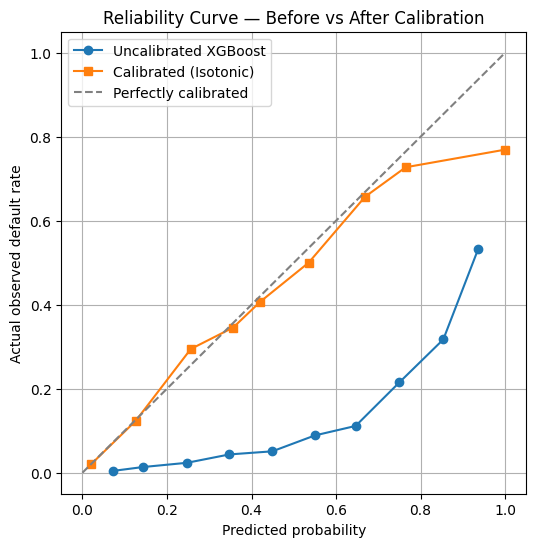

In [17]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true_before, prob_pred_before = calibration_curve(y_eval, y_prob_uncalibrated, n_bins=10)
prob_true_after, prob_pred_after = calibration_curve(y_eval, y_prob_calibrated, n_bins=10)

plt.figure(figsize=(6,6))
plt.plot(prob_pred_before, prob_true_before, marker='o', label='Uncalibrated XGBoost')
plt.plot(prob_pred_after, prob_true_after, marker='s', label='Calibrated (Isotonic)')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')
plt.xlabel("Predicted probability")
plt.ylabel("Actual observed default rate")
plt.title("Reliability Curve — Before vs After Calibration")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
from sklearn.metrics import roc_auc_score, recall_score

# Compare ranking performance before vs after calibration, same eval set
auc_before = roc_auc_score(y_eval, y_prob_uncalibrated)
auc_after = roc_auc_score(y_eval, y_prob_calibrated)

y_pred_before = (y_prob_uncalibrated >= 0.5).astype(int)
y_pred_after = (y_prob_calibrated >= 0.5).astype(int)

recall_before = recall_score(y_eval, y_pred_before)
recall_after = recall_score(y_eval, y_pred_after)

print(f"ROC-AUC  — before: {auc_before:.4f}  after: {auc_after:.4f}")
print(f"Recall@0.5 — before: {recall_before:.4f}  after: {recall_after:.4f}")

ROC-AUC  — before: 0.8616  after: 0.8607
Recall@0.5 — before: 0.7692  after: 0.1913


In [19]:
from sklearn.metrics import confusion_matrix

thresholds = np.arange(0.05, 0.95, 0.01)
results_calibrated = []

for t in thresholds:
    y_pred = (y_prob_calibrated >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_eval, y_pred).ravel()
    expected_loss = (fn * COST_FN) + (fp * COST_FP)
    results_calibrated.append({"threshold": t, "fn": fn, "fp": fp, "expected_loss": expected_loss})

results_calibrated_df = pd.DataFrame(results_calibrated)
optimal_row_calibrated = results_calibrated_df.loc[results_calibrated_df["expected_loss"].idxmin()]
print(optimal_row_calibrated)

threshold           0.12
fn                387.00
fp               1267.00
expected_loss    3202.00
Name: 7, dtype: float64


In [20]:
for t in [0.02, 0.05, 0.08, 0.12, 0.2, 0.3, 0.5]:
    row = results_calibrated_df.loc[(results_calibrated_df["threshold"] - t).abs().idxmin()]
    print(row.to_dict())

{'threshold': 0.05, 'fn': 208.0, 'fp': 3201.0, 'expected_loss': 4241.0}
{'threshold': 0.05, 'fn': 208.0, 'fp': 3201.0, 'expected_loss': 4241.0}
{'threshold': 0.08000000000000002, 'fn': 235.0, 'fp': 2747.0, 'expected_loss': 3922.0}
{'threshold': 0.12000000000000001, 'fn': 387.0, 'fp': 1267.0, 'expected_loss': 3202.0}
{'threshold': 0.2, 'fn': 515.0, 'fp': 728.0, 'expected_loss': 3303.0}
{'threshold': 0.30000000000000004, 'fn': 677.0, 'fp': 340.0, 'expected_loss': 3725.0}
{'threshold': 0.5000000000000001, 'fn': 799.0, 'fp': 134.0, 'expected_loss': 4129.0}


In [21]:
import joblib
joblib.dump(calibrated_model, "../models/xgboost_calibrated.pkl")
print("Calibrated model saved.")

FileNotFoundError: [Errno 2] No such file or directory: '../models/xgboost_calibrated.pkl'

In [22]:
import joblib
joblib.dump(calibrated_model, "models/xgboost_calibrated.pkl")
print("Calibrated model saved.")

Calibrated model saved.


In [23]:
Get-ChildItem models\xgboost_calibrated.pkl

SyntaxError: invalid syntax (1613120465.py, line 1)

In [24]:
import os
print(os.path.exists("models/xgboost_calibrated.pkl"))
print(os.path.getsize("models/xgboost_calibrated.pkl"))

True
346288


In [25]:
from scipy.stats import ks_2samp

# Split predicted probabilities by actual outcome
scores_default = y_prob[y_test == 1]
scores_nondefault = y_prob[y_test == 0]

ks_stat, ks_pvalue = ks_2samp(scores_default, scores_nondefault)
print("KS Statistic (uncalibrated XGBoost):", ks_stat)

KS Statistic (uncalibrated XGBoost): 0.5647118659523869


In [26]:
from sklearn.metrics import roc_auc_score

auc_uncalibrated = roc_auc_score(y_test, y_prob)
gini_uncalibrated = 2 * auc_uncalibrated - 1

print("ROC-AUC (uncalibrated):", auc_uncalibrated)
print("Gini (uncalibrated):", gini_uncalibrated)

ROC-AUC (uncalibrated): 0.8597090904222133
Gini (uncalibrated): 0.7194181808444267
